In [1]:
# Decision tree benchmark: 3-fold evaluation on heart-sound features
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = next((candidate for candidate in (Path.cwd(), *Path.cwd().parents) if (candidate / "features_normal_train.data").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the CardioAgent-Ops project.")
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from benchmark_common import CLASS_NAMES, FEATURE_NAMES, load_heart_sound_features


In [2]:
# The same 22 features used by the SVM: duration, SNR, and 20 Mel-band means.
X, y = load_heart_sound_features(PROJECT_ROOT)
print(f"X: {X.shape}; normal: {(y == 0).sum()}; abnormal: {(y == 1).sum()}")
pd.DataFrame(X, columns=FEATURE_NAMES).head()


X: (3785, 22); normal: 1016; abnormal: 2769


,duration,snr,mel_1,mel_2,mel_3,mel_4,mel_5,mel_6,mel_7,mel_8,...,mel_11,mel_12,mel_13,mel_14,mel_15,mel_16,mel_17,mel_18,mel_19,mel_20
0,8.8075,0.006710,-16.841677,-19.688116,-21.856184,-23.289961,-24.160439,-24.869219,-26.234570,-26.597385,...,-28.332466,-30.052866,-31.126770,-31.872873,-32.015453,-32.058754,-32.296711,-33.377346,-34.338982,-37.693394
1,4.6805,0.026340,-15.626101,-17.922735,-23.287146,-25.556116,-26.411135,-27.813147,-32.265320,-34.176247,...,-36.818405,-39.425304,-41.588394,-42.392761,-43.119179,-42.211365,-40.343189,-43.195286,-42.899567,-45.423008
2,6.2100,-0.005204,-10.242869,-15.327780,-22.351292,-25.240929,-25.592972,-27.282160,-30.807951,-32.663952,...,-37.543346,-38.923923,-40.303925,-41.350079,-42.948063,-43.463230,-44.061802,-46.509251,-47.638233,-51.660030
3,9.9025,-0.000561,-8.903273,-12.322722,-21.110411,-25.281317,-27.352064,-29.352558,-29.425699,-29.711435,...,-37.268936,-39.308430,-40.764217,-42.506432,-43.755527,-44.263844,-43.572689,-46.335548,-47.275906,-51.267986
4,5.1205,-0.005855,-9.271482,-11.864514,-21.290575,-25.446054,-28.036386,-30.982750,-31.445566,-32.264351,...,-37.496056,-39.882446,-42.946991,-44.928062,-47.092705,-48.155983,-47.683861,-51.837048,-53.428150,-57.216736


,fold,accuracy,precision,recall,f1
0,1,0.807,0.883,0.848,0.865
1,2,0.795,0.855,0.866,0.861
2,3,0.787,0.857,0.850,0.854


Mean metrics:


,accuracy,precision,recall,f1
mean,0.796,0.865,0.855,0.86


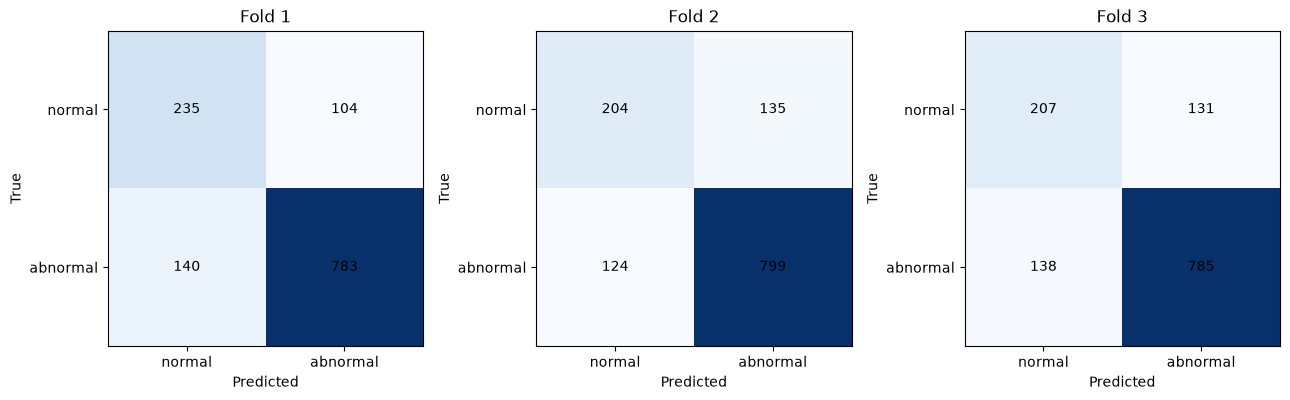

In [3]:
# Three stratified folds keep the normal/abnormal proportion in every test set.
def make_tree():
    return DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=1)

splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
fold_metrics, fold_confusions = [], []
for fold, (train_index, test_index) in enumerate(splitter.split(X, y), start=1):
    tree = make_tree()
    tree.fit(X[train_index], y[train_index])
    predicted = tree.predict(X[test_index])
    metrics = {
        "fold": fold,
        "accuracy": float(accuracy_score(y[test_index], predicted)),
        "precision": float(precision_score(y[test_index], predicted, zero_division=0)),
        "recall": float(recall_score(y[test_index], predicted, zero_division=0)),
        "f1": float(f1_score(y[test_index], predicted, zero_division=0)),
    }
    fold_metrics.append(metrics)
    fold_confusions.append({"fold": fold, "labels": CLASS_NAMES, "matrix": confusion_matrix(y[test_index], predicted, labels=[0, 1]).tolist()})

results = pd.DataFrame(fold_metrics)
display(results.round(3))
print("Mean metrics:")
display(results[["accuracy", "precision", "recall", "f1"]].mean().to_frame("mean").T.round(3))

# Keep a visual version of every fold's confusion matrix for MLflow.
figure, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, item in zip(axes, fold_confusions):
    matrix = np.asarray(item["matrix"])
    axis.imshow(matrix, cmap="Blues")
    axis.set_title(f"Fold {item['fold']}")
    axis.set_xticks([0, 1], CLASS_NAMES)
    axis.set_yticks([0, 1], CLASS_NAMES)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("True")
    for row, column in np.ndindex(matrix.shape):
        axis.text(column, row, str(matrix[row, column]), ha="center", va="center")
figure.tight_layout()
confusion_figure_path = PROJECT_ROOT / "decision_tree_confusion_matrices.png"
figure.savefig(confusion_figure_path, dpi=150)
plt.show()


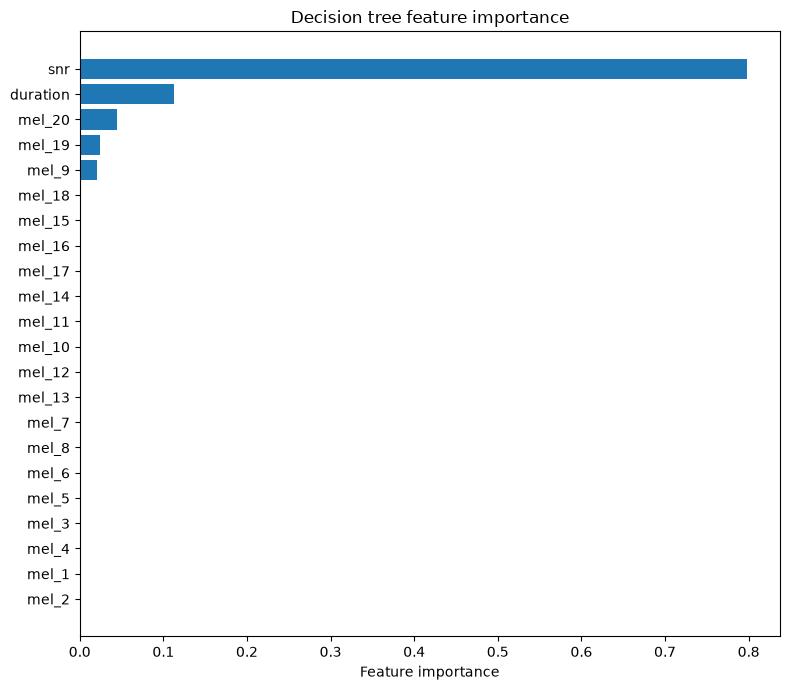

In [4]:
# Fit one final tree on all samples and save its feature-importance chart.
final_tree = make_tree()
final_tree.fit(X, y)
importance_order = np.argsort(final_tree.feature_importances_)
plt.figure(figsize=(8, 7))
plt.barh(np.arange(len(FEATURE_NAMES)), final_tree.feature_importances_[importance_order])
plt.yticks(np.arange(len(FEATURE_NAMES)), np.asarray(FEATURE_NAMES)[importance_order])
plt.xlabel("Feature importance")
plt.title("Decision tree feature importance")
plt.tight_layout()
figure_path = PROJECT_ROOT / "decision_tree_feature_importance.png"
plt.savefig(figure_path, dpi=150)
plt.show()


In [5]:
# ---- MLflow (Service 6) ----
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")
mlflow.set_system_metrics_sampling_interval(1)
mlflow.enable_system_metrics_logging()

with mlflow.start_run(run_name="decision_tree", log_system_metrics=True) as run:
    mlflow.set_tags({
        "model": "DecisionTreeClassifier",
        "task": "pcg_normal_vs_abnormal",
        "evaluation": "3_fold_cross_validation",
        "feature_set": "duration_snr_20_mel_means",
    })
    mlflow.log_params({
        "max_depth": 3, "class_weight": "balanced", "random_state": 1,
        "n_folds": 3, "n_features": int(X.shape[1]), "n_samples": int(len(y)),
        "features": "duration + snr + 20 mel means",
    })
    for metric in ("accuracy", "precision", "recall", "f1"):
        mlflow.log_metric(f"mean_{metric}", float(results[metric].mean()))
    for row in fold_metrics:
        for metric in ("accuracy", "precision", "recall", "f1"):
            mlflow.log_metric(f"fold_{metric}", row[metric], step=row["fold"])
    mlflow.log_dict({"folds": fold_metrics}, "reports/cv_metrics.json")
    mlflow.log_dict({"folds": fold_confusions}, "reports/confusion_matrices.json")
    mlflow.log_dict({"feature_names": FEATURE_NAMES, "n_splits": 3, "shuffle": True, "random_state": 1}, "config/training_config.json")
    mlflow.log_artifact(str(figure_path), artifact_path="figures")
    mlflow.log_artifact(str(confusion_figure_path), artifact_path="figures")
    mlflow.sklearn.log_model(final_tree, name="decision_tree_model", serialization_format="cloudpickle", signature=infer_signature(X[:5], final_tree.predict(X[:5])), input_example=X[:5])
    print(f"Logged decision tree run: {run.info.run_id}")


2026/11/14 09:25:45 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/14 09:25:45 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/14 09:25:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/14 09:25:53 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/14 09:25:53 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


Logged decision tree run: a1550ba943f14761bc58dbff8e1768b2
🏃 View run decision_tree at: http://localhost:5000/#/experiments/1/runs/a1550ba943f14761bc58dbff8e1768b2
🧪 View experiment at: http://localhost:5000/#/experiments/1
